# 🗳️ Boatos em Rede: simulando a propagação de fake news com agentes inteligentes

**Disciplina:** Inteligência Artificial · **Duração:** 4 semanas · **Equipes:** até 4 pessoas
**Ferramentas:** Python, [Mesa](https://mesa.readthedocs.io) (modelagem baseada em agentes) e [NetworkX](https://networkx.org) (redes), no Google Colab

---

Neste trabalho vocês vão construir uma **sociedade artificial**: centenas de eleitores-agentes conectados numa rede social, trocando uma notícia falsa. Cada agente segue regras simples (acreditar ou não, compartilhar ou não, checar ou não). Ninguém controla o todo, mas, ao rodar a simulação, aparece um comportamento coletivo: o boato **viraliza** ou **morre**.

Depois vocês vão testar, com dados da simulação, as estratégias que o mundo real usa contra a desinformação: checagem de fatos, limite de encaminhamento e educação midiática. No fim, vão avaliar os resultados e propor soluções.

> **Por que isso é IA?** No livro de Russell & Norvig, um *agente* é qualquer coisa que percebe o ambiente e age sobre ele. Aqui, cada eleitor é um agente; a rede social é o ambiente. Modelagem baseada em agentes é uma técnica usada em pesquisa sobre epidemias, mercados e, cada vez mais, sobre desinformação.

**Adicione o nome e matrícula dos membros da equipe nesta célula**


1.   Nome JORGE RODRIGUES MARTINS
2.   Nome MARCIO DE SOUZA NONATO FILHO
3.   Nome YURI ARMARILDO
4.



## 📅 Cronograma

| Semana | Tema | O que a equipe faz | Entrega no notebook |
|---|---|---|---|
| **1** | Contexto e modelo base | Ler as notícias, rodar o modelo, comparar tipos de rede | Experimentos 1 a 3 + registros |
| **2** | Intervenções das plataformas | Programar a **checagem de fatos** (TODO 1) e o **limite de encaminhamento** (TODO 2) | Experimentos 4 e 5 + registros |
| **3** | Educação midiática e proposta da equipe | Programar o **letramento midiático** (TODO 3) e montar uma estratégia com orçamento | Experimentos 6 e 7 + registros |
| **4** | Parte discursiva | Avaliar os resultados e discutir soluções contra fake news | Questões D1 a D6 |

**Entrega final:** o notebook `.ipynb` com todas as células executadas (Arquivo → Baixar → Baixar o .ipynb). Adicione o notebook em um repositório no Github e envie o link no ambiente virtual da disciplina.

## 🧭 Como usar este notebook (leia antes de começar)

1. Abra no Google Colab e faça uma cópia: **Arquivo → Salvar uma cópia no Drive**.
2. Um notebook tem dois tipos de célula: **texto** (como esta) e **código** (fundo cinza).
3. Para rodar uma célula de código: clique nela e aperte **Shift + Enter**.
4. Rode as células **na ordem**, de cima para baixo. Se algo der erro estranho, use **Ambiente de execução → Reiniciar e executar tudo**.
5. Células marcadas com ✏️ **TODO** são as que vocês precisam completar. Células marcadas com 📝 **Registro** são para escrever respostas em texto (dê dois cliques para editar).
6. Vocês **não precisam entender cada linha** do código do modelo. Precisam entender as **regras** e saber **mudar parâmetros**. A colinha de Python logo abaixo cobre o necessário.

### 🐍 Colinha de Python (o mínimo para este trabalho)

```python
x = 0.3                         # variável: guarda um valor
cenario = {"prob_checagem": 0.1, "tipo_rede": "sem_escala"}   # dicionário: pares "nome": valor
cenario["prob_checagem"]        # lê o valor -> 0.1
if x > 0.2:                     # condição (atenção aos 4 espaços de recuo na linha de baixo)
    print("maior")
self.random.random()            # sorteia um número entre 0 e 1
self.random.random() < 0.3      # True em 30% das vezes -> é assim que representamos "uma chance de 30%"
```

---
# 📰 SEMANA 1 — Contexto: por que isso importa?

Antes de programar, leiam as notícias e estudos abaixo. Todos os links foram conferidos em outubro de 2026. Cada caso tem uma **ligação com o modelo**: vocês vão reencontrar essas ideias nos experimentos.

### 1. Notícia falsa viaja mais rápido que a verdadeira
O maior estudo já feito sobre o tema (MIT, publicado na revista *Science* em 2018) analisou cerca de 126 mil cascatas de notícias no Twitter entre 2006 e 2017. Resultado: notícias falsas tiveram **cerca de 70% mais chance de serem retuitadas**, e as verdadeiras levaram **cerca de seis vezes mais tempo** para alcançar 1.500 pessoas. Um detalhe importante: retirando os robôs (*bots*) da amostra, a diferença continuou. **Quem espalha são as pessoas.**
🔗 [MIT News — Study: On Twitter, false news travels faster than true stories](https://news.mit.edu/2018/study-twitter-false-news-travels-faster-true-stories-0308)
**Ligação com o modelo:** o parâmetro `prob_compartilhar` representa essa "atração" pela novidade.

### 2. Um boato que matou: Guarujá, 2014
Em maio de 2014, uma página local no Facebook com mais de 24 mil seguidores publicou um retrato falado de uma suposta sequestradora de crianças, ligado a um boato que circulava no bairro. O retrato era antigo, de outro caso, de outro estado. A dona de casa **Fabiane Maria de Jesus** foi confundida com a suspeita, agredida por dezenas de pessoas e morreu. A própria página já havia informado que a polícia não tinha registro de crianças desaparecidas, mas o boato já tinha se espalhado.
🔗 [Global Voices — How an internet rumor in Brazil killed Fabiane Maria de Jesus](https://globalvoices.org/2014/05/27/how-an-internet-rumor-in-brazil-killed-fabiane-maria-de-jesus/)
**Ligação com o modelo:** um perfil com muitos seguidores é um **nó de alto grau** (um "influenciador"). Isso é o Experimento 3.

### 3. Desinformação sobre vacinas
Pesquisa da Avaaz com a Sociedade Brasileira de Imunizações (2019) apontou que **67% dos brasileiros acreditavam em pelo menos uma informação falsa sobre vacinas** (73% entre quem se informa por redes sociais ou WhatsApp) e que **13% deixaram de se vacinar ou de vacinar uma criança**, cerca de 21 milhões de pessoas.
🔗 [Avaaz/SBIm — As fake news estão nos deixando doentes?](https://familia.sbim.org.br/images/files/po-avaaz-relatorio-antivacina.pdf)
**Ligação com o modelo:** o parâmetro `prob_acreditar` e a ideia de **letramento midiático** (Semana 3).

### 4. Boatos no meio de uma tragédia: enchentes no Rio Grande do Sul, 2024
Durante as enchentes de maio de 2024, circularam afirmações falsas de que doações estavam sendo barradas por falta de nota fiscal, que barcos e jet skis de voluntários estavam sendo recolhidos e que helicópteros estavam impedidos de ajudar. Os órgãos envolvidos desmentiram cada uma, mas os boatos geravam medo e podiam desestimular doações e resgates justamente quando a ajuda era mais urgente.
🔗 [CNN Brasil — Fake news atrapalham ajuda para vítimas das enchentes no RS](https://www.cnnbrasil.com.br/nacional/fake-news-atrapalham-ajuda-para-vitimas-das-enchentes-no-rs/)
**Ligação com o modelo:** a **checagem de fatos** (Semana 2) e o quanto ela precisa ser rápida.

### 5. Uma mudança de design que funcionou: o limite do WhatsApp
Em 2019 o WhatsApp reduziu o encaminhamento de mensagens de 20 para **5 conversas** por vez, e o volume de encaminhamentos caiu cerca de 25%. Em 2020, mensagens "altamente encaminhadas" passaram a poder ir para **apenas 1 conversa**, e a empresa informou uma **queda de 70%** nesse tipo de mensagem.
🔗 [Tecnoblog — WhatsApp tem queda de 70% em mensagens encaminhadas após limite](https://tecnoblog.net/335805/whatsapp-tem-queda-mensagens-encaminhadas-apos-novo-limite/)
**Ligação com o modelo:** o parâmetro `limite_encaminhamento` (Semana 2).

### 6. Deepfakes nas eleições de 2026
O TSE exige que propaganda eleitoral feita ou alterada por IA informe isso de forma explícita e proíbe deepfakes realistas usados para favorecer ou prejudicar candidaturas, **mesmo com rótulo**. Nas 72 horas antes e 24 horas depois da votação, fica proibido publicar novos conteúdos sintéticos com imagem ou voz de candidatos. Em setembro de 2026, o tribunal esclareceu que caricaturas e sátiras claramente estilizadas ficam fora da proibição.
🔗 [A Crítica — Regras do TSE para IA e deepfakes nas eleições 2026](https://acritica.net/eleicoes-2026/tse-ia-deepfakes/) · [Portal de Prefeitura — TSE fixa tese sobre deepfake](https://portaldeprefeitura.com.br/bastidores-da-politica/tse/tse-fixa-tese-sobre-deepfake-delimita-regra-para-eleicoes/632270/)
**Ligação com o modelo:** um deepfake é um boato **mais convincente**, ou seja, `prob_acreditar` mais alto. Vocês vão discutir isso na questão D6.

## ⚙️ Preparando o ambiente
Rode a célula abaixo uma vez (leva alguns segundos). Ela instala o Mesa numa **versão fixa**: o Mesa mudou bastante na versão 3, e muitos tutoriais da internet usam a versão antiga, que não funciona aqui.

In [2]:
%pip install -q "mesa==3.5.1" networkx matplotlib pandas

import mesa
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Mesa", mesa.__version__, "| NetworkX", nx.__version__, "→ tudo pronto!")

Mesa 3.5.1 | NetworkX 3.7 → tudo pronto!


## 🧠 O modelo: as regras do jogo

Cada eleitor está sempre em **um de três estados**:

| Estado | Significado | Cor nos desenhos |
|---|---|---|
| 🔘 **Suscetível** | Ainda não acreditou no boato | cinza |
| 🔴 **Espalhador** | Acreditou e está compartilhando | vermelho |
| 🔵 **Cético** | Deixou de espalhar (perdeu o interesse ou descobriu que era falso) e não volta a acreditar | azul |

A cada **rodada** (um "passo" da simulação), cada espalhador, em ordem aleatória:
1. **Checa os fatos** com chance `prob_checagem`. Se checar, vira cético e para por aqui. *(Semana 2)*
2. **Escolhe para quem enviar**: cada contato tem chance `prob_compartilhar` de receber a mensagem. Se houver `limite_encaminhamento`, envia no máximo para esse número de contatos. *(Semana 2)*
3. Cada contato suscetível que recebe **acredita** com chance `prob_acreditar`. Se o contato tiver **letramento midiático**, essa chance é multiplicada por `fator_letramento`. *(Semana 3)*
4. **Perde o interesse** com chance `prob_desistir` e vira cético.

A **rede** pode ser de três tipos (todos com o mesmo número médio de contatos):
- `"aleatoria"`: as amizades são sorteadas ao acaso;
- `"mundo_pequeno"`: as pessoas se conectam principalmente com "vizinhos" (como um bairro ou uma turma), mais algumas conexões distantes;
- `"sem_escala"`: a maioria tem poucos contatos e **poucos perfis concentram muitos**, como influenciadores. É o tipo mais parecido com redes sociais reais.

A medida principal é o **alcance**: a porcentagem da população que **chegou a acreditar** no boato.

### O código do modelo
Rodem a célula abaixo. Não precisam alterá-la: leiam os comentários e tentem reconhecer as regras acima. As funções `checar_fatos`, `escolher_destinatarios` e `receber_boato` estão **incompletas de propósito**: vocês vão melhorá-las nas semanas 2 e 3.

In [3]:
SUSCETIVEL, ESPALHADOR, CETICO = "Suscetível", "Espalhador", "Cético"


class Eleitor(mesa.Agent):
    """Um eleitor-agente. Ele percebe as mensagens dos contatos e decide o que fazer."""

    def __init__(self, model, no):
        super().__init__(model)        # registra o agente no modelo
        self.no = no                   # posição (nó) do eleitor na rede
        self.estado = SUSCETIVEL
        self.letrado = False           # tem letramento midiático? (Semana 3)

    def vizinhos(self):
        """Lista dos eleitores conectados a este na rede."""
        return [self.model.eleitor_do_no[v] for v in self.model.rede.neighbors(self.no)]

    # ---------- funções do agente ----------
    def receber_boato(self):
        """Um contato enviou o boato. Acreditar ou não? (TODO 3 na Semana 3)"""
        if self.estado != SUSCETIVEL:
            return
        chance = self.model.prob_acreditar
        if self.random.random() < chance:
            self.estado = ESPALHADOR

    def checar_fatos(self):
        """TODO 1 (Semana 2): o agente checa os fatos com chance prob_checagem."""
        return self.random.random() < self.model.prob_checagem

    def escolher_destinatarios(self):
        """TODO 2 (Semana 2): limita o número máximo de contatos que recebem o encaminhamento."""
        quer_enviar = [v for v in self.vizinhos() if self.random.random() < self.model.prob_compartilhar]
        limite = self.model.limite_encaminhamento
        if limite is not None and len(quer_enviar) > limite:
            quer_enviar = self.random.sample(quer_enviar, limite)
        return quer_enviar

    # ---------- o comportamento do espalhador em uma rodada ----------
    def step(self):
        if self.checar_fatos():                # regra 1
            self.estado = CETICO
            return
        for contato in self.escolher_destinatarios(): # regra 2
            contato.receber_boato()                   # regra 3
        if self.random.random() < self.model.prob_desistir: # regra 4
            self.estado = CETICO


def porcentagem(modelo, estado):
    return 100 * sum(a.estado == estado for a in modelo.agents) / len(modelo.agents)


class ModeloBoato(mesa.Model):
    """O mundo: a rede social, os eleitores e as regras gerais."""

    def __init__(self, n_eleitores=300, tipo_rede="sem_escala", grau_medio=6,
                 n_iniciais=5, inicio="aleatorio",
                 prob_compartilhar=0.10, prob_acreditar=0.50, prob_desistir=0.15,
                 prob_checagem=0.0, limite_encaminhamento=None,
                 fracao_letrados=0.0, fator_letramento=0.3, semente=None):
        super().__init__(rng=semente)
        self.prob_compartilhar = prob_compartilhar
        self.prob_acreditar = prob_acreditar
        self.prob_desistir = prob_desistir
        self.prob_checagem = prob_checagem
        self.limite_encaminhamento = limite_encaminhamento
        self.fator_letramento = fator_letramento

        # 1) cria a rede social com o NetworkX
        s = self.random.randrange(10**9)
        if tipo_rede == "aleatoria":
            self.rede = nx.erdos_renyi_graph(n_eleitores, grau_medio / (n_eleitores - 1), seed=s)
        elif tipo_rede == "mundo_pequeno":
            self.rede = nx.watts_strogatz_graph(n_eleitores, grau_medio, 0.1, seed=s)
        elif tipo_rede == "sem_escala":
            self.rede = nx.barabasi_albert_graph(n_eleitores, grau_medio // 2, seed=s)
        else:
            raise ValueError("tipo_rede deve ser 'aleatoria', 'mundo_pequeno' ou 'sem_escala'")

        # 2) cria um eleitor para cada nó da rede
        self.eleitor_do_no = {no: Eleitor(self, no) for no in self.rede.nodes}
        eleitores = list(self.eleitor_do_no.values())

        # 3) sorteia quem tem letramento midiático
        for e in self.random.sample(eleitores, round(fracao_letrados * n_eleitores)):
            e.letrado = True

        # 4) escolhe quem começa espalhando o boato
        if inicio == "influenciadores":
            mais_conectados = sorted(self.rede.nodes, key=self.rede.degree, reverse=True)[:n_iniciais]
            iniciais = [self.eleitor_do_no[n] for n in mais_conectados]
        else:
            iniciais = self.random.sample(eleitores, n_iniciais)
        for e in iniciais:
            e.estado = ESPALHADOR

        # 5) registra os indicadores a cada rodada
        self.coletor = mesa.DataCollector(model_reporters={
            "Suscetível": lambda m: porcentagem(m, SUSCETIVEL),
            "Espalhador": lambda m: porcentagem(m, ESPALHADOR),
            "Cético": lambda m: porcentagem(m, CETICO),
        })
        self.coletor.collect(self)

    def step(self):
        """Uma rodada: só quem é espalhador age."""
        self.agents.select(lambda a: a.estado == ESPALHADOR).shuffle_do("step")
        self.coletor.collect(self)


print("Modelo carregado ✅")

Modelo carregado ✅


### Ferramentas de experimento
Esta célula cria três funções que vocês vão usar o tempo todo. Rodem e sigam em frente.
- `mostrar_evolucao(cenario)` desenha a rede em quatro momentos da simulação.
- `comparar_cenarios(cenarios)` roda cada cenário **50 vezes** (com sementes diferentes), faz a média, desenha os gráficos e mostra uma tabela-resumo.
- `custo_da_proposta(cenario)` será usada na Semana 3.

In [21]:
CORES = {SUSCETIVEL: "lightgray", ESPALHADOR: "crimson", CETICO: "royalblue"}


def rodar_uma_vez(passos=60, semente=0, **parametros):
    modelo = ModeloBoato(semente=semente, **parametros)
    for _ in range(passos):
        modelo.step()
    dados = modelo.coletor.get_model_vars_dataframe()
    dados["Alcance"] = 100 - dados["Suscetível"]
    return dados


def mostrar_evolucao(cenario=None, momentos=(0, 5, 15, 40), semente=1):
    """Desenha a rede em alguns momentos da simulação."""
    cenario = cenario or {}
    modelo = ModeloBoato(semente=semente, **cenario)
    posicoes = nx.spring_layout(modelo.rede, seed=7)
    fig, eixos = plt.subplots(1, len(momentos), figsize=(4.2 * len(momentos), 4.2))
    passo = 0
    for eixo, momento in zip(eixos, momentos):
        while passo < momento:
            modelo.step()
            passo += 1
        cores = [CORES[modelo.eleitor_do_no[n].estado] for n in modelo.rede.nodes]
        tamanhos = [8 + 2 * modelo.rede.degree(n) for n in modelo.rede.nodes]
        nx.draw_networkx(modelo.rede, posicoes, ax=eixo, node_color=cores, node_size=tamanhos,
                         with_labels=False, width=0.2, edge_color="#bbbbbb")
        alcance = 100 - porcentagem(modelo, SUSCETIVEL)
        eixo.set_title(f"Rodada {momento} | alcance {alcance:.0f}%")
        eixo.axis("off")
    plt.suptitle("Cinza = suscetível · Vermelho = espalhador · Azul = cético  (bolinhas maiores = mais contatos)")
    plt.tight_layout()
    plt.show()


def comparar_cenarios(cenarios, passos=60, repeticoes=50):
    """Roda cada cenário várias vezes, mostra gráficos e devolve uma tabela-resumo."""
    medias, linhas = {}, []
    for nome, parametros in cenarios.items():
        execucoes = [rodar_uma_vez(passos, semente=s, **parametros) for s in range(repeticoes)]
        media = pd.concat(execucoes).groupby(level=0).mean()
        medias[nome] = media
        finais = pd.Series([e["Alcance"].iloc[-1] for e in execucoes])
        linhas.append({
            "Cenário": nome,
            "Alcance final médio (%)": round(finais.mean(), 1),
            "Desvio padrão": round(finais.std(), 1),
            "Pico de espalhadores (%)": round(media["Espalhador"].max(), 1),
            "Rodada do pico": int(media["Espalhador"].idxmax()),
            "Boato morreu cedo (% das simulações)": round(100 * (finais < 10).mean()),
        })

    fig, (g1, g2) = plt.subplots(1, 2, figsize=(13, 4.5))
    for nome, media in medias.items():
        g1.plot(media.index, media["Alcance"], label=nome, linewidth=2)
        g2.plot(media.index, media["Espalhador"], label=nome, linewidth=2)
    g1.set_title("Alcance acumulado (% que acreditou)")
    g2.set_title("Espalhadores ativos (%)")
    for g in (g1, g2):
        g.set_xlabel("Rodada")
        g.grid(alpha=0.3)
    g1.set_ylim(0, 100)
    g1.legend()
    plt.tight_layout()
    plt.show()

    tabela = pd.DataFrame(linhas).set_index("Cenário")
    display(tabela)
    return tabela


# ----- custos (fictícios) para a Semana 3 -----
ORCAMENTO = 15
CUSTO_LIMITE = {None: 0, 5: 1, 4: 2, 3: 3, 2: 5, 1: 8}


def custo_da_proposta(cenario):
    checagem = round(cenario.get("prob_checagem", 0) * 100)       # 1 ponto por ponto percentual
    limite = CUSTO_LIMITE.get(cenario.get("limite_encaminhamento"), 99)
    letramento = round(cenario.get("fracao_letrados", 0) * 10) * 2  # 2 pontos a cada 10% da população
    total = checagem + limite + letramento
    print(f"Checagem: {checagem} pts | Limite: {limite} pts | Letramento: {letramento} pts")
    print(f"TOTAL: {total} de {ORCAMENTO} pontos →", "✅ dentro do orçamento" if total <= ORCAMENTO else "❌ acima do orçamento")
    return total


print("Ferramentas carregadas ✅")

Ferramentas carregadas ✅


## 🧪 Experimento 1 — O boato se espalhando
Rodem a célula e observem a rede. Depois, **mudem a `semente`** (por exemplo, para 2, 3 e 4) e rodem de novo.

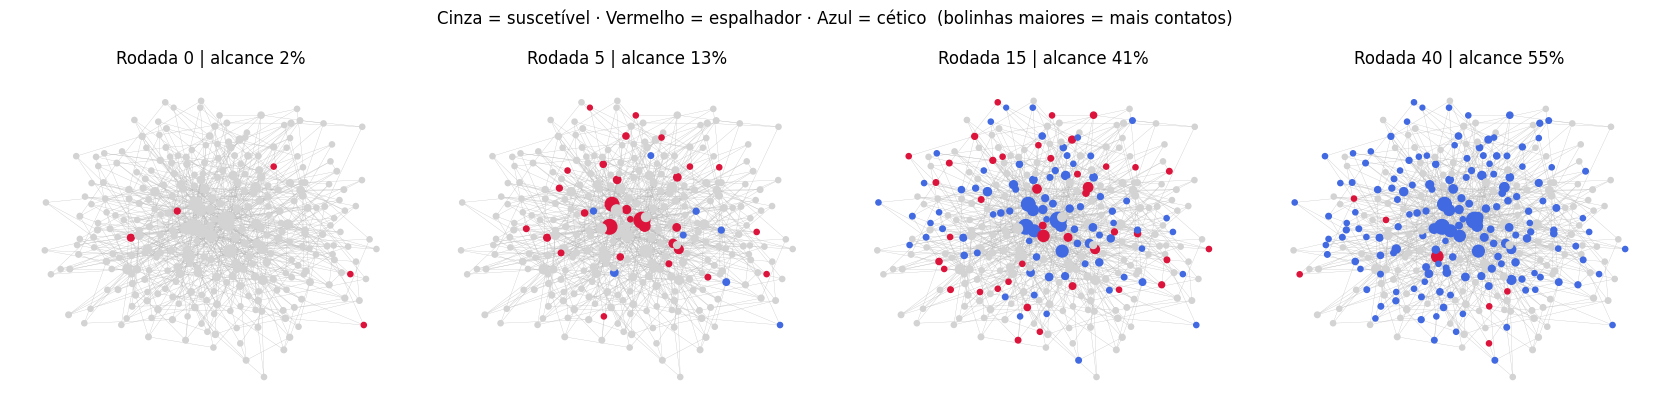

In [ ]:
mostrar_evolucao({"tipo_rede": "sem_escala"}, semente=1)

📝 **Registro 1.** O que muda quando vocês trocam a semente? Em algum caso o boato "morreu" logo no início? Por que, então, faz sentido rodar **várias** simulações e tirar a média, em vez de olhar uma só?

*Resposta da equipe:*

Mudança ao trocar a semente: A semente (seed) controla o gerador estocástico. Ao alterá-la, muda-se a topologia exata das conexões da rede, os 5 nós inicialmente infetados e as decisões probabilísticas de partilha a cada rodada.

O boato morre no início? Sim. Se os nós sorteados inicialmente tiverem poucos contactos ou se as probabilidades de transmissão falharem na rodada inicial, o boato fica sem espalhadores ativos e extingue-se precocemente.

Por que rodar várias simulações e tirar a média? Como o sistema é estocástico, uma única execução pode representar um caso extremo de sorte ou azar. A média de várias simulações (método de Monte Carlo) permite obter o comportamento estatístico esperado do modelo.

## 🧪 Experimento 2 — A forma da rede importa?
Mesmo número de pessoas, mesmo número médio de contatos, mesmas regras. Só muda **como** as pessoas estão conectadas.

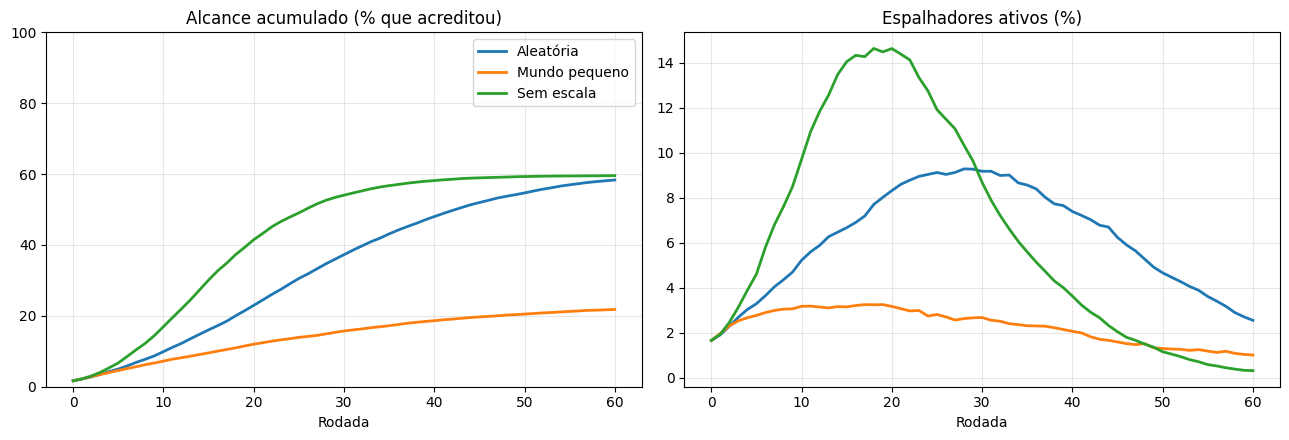

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Aleatória,58.3,13.8,9.3,28,0
Mundo pequeno,21.8,11.4,3.3,17,20
Sem escala,59.6,12.7,14.6,18,2


In [ ]:
cenarios = {
    "Aleatória":     {"tipo_rede": "aleatoria"},
    "Mundo pequeno": {"tipo_rede": "mundo_pequeno"},
    "Sem escala":    {"tipo_rede": "sem_escala"},
}
tabela_redes = comparar_cenarios(cenarios)

📝 **Registro 2.** Em qual rede o boato teve maior alcance? Em qual ele chegou ao pico mais rápido? Por que a rede "mundo pequeno" segura melhor o boato? (Dica: pensem em quantos contatos em comum vocês têm com seus amigos.)

*Resposta da equipe:*

Maior alcance: Redes "Sem escala" (59.6%) e "Aleatória" (58.3%).   
Pico mais rápido: Na rede "Sem escala", atingindo o pico de 14.6% de espalhadores ativos logo na rodada 18.   
Por que "Mundo Pequeno" segura o boato: Por apresentar alto agrupamento local (comunidades densas). A informação circula de forma redundante entre amigos em comum e não encontra "pontes" fáceis para alcançar outros grupos.
A população local torna-se cética antes que o boato consiga propagar-se globalmente, fazendo com que o boato morra cedo em 20% dos casos.  

## 🧪 Experimento 3 — E se o boato começar por um influenciador?
Agora o boato nasce nos 5 perfis **mais conectados** da rede (como a página com 24 mil seguidores do caso de Guarujá), em vez de 5 pessoas sorteadas.

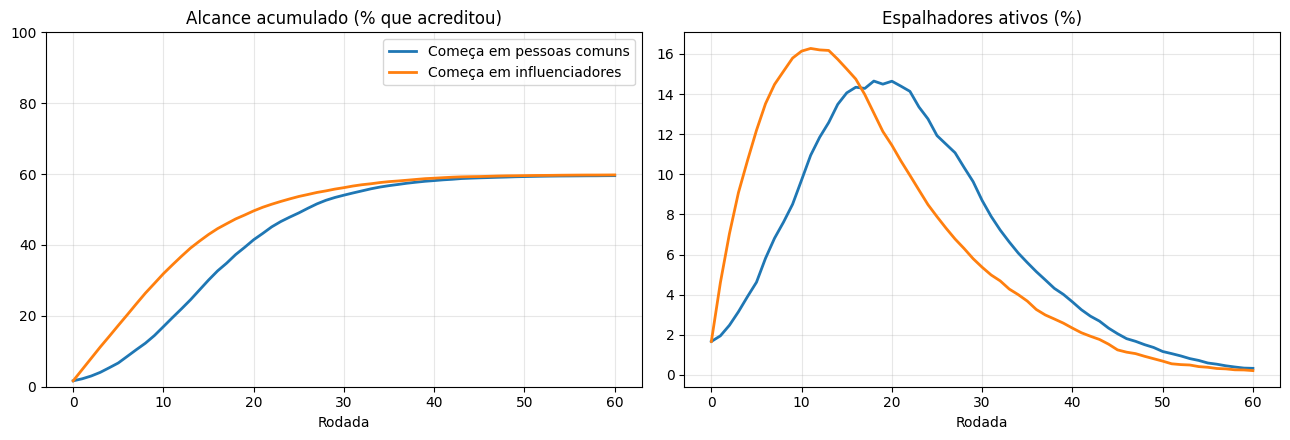

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Começa em pessoas comuns,59.6,12.7,14.6,18,2
Começa em influenciadores,59.8,7.1,16.3,11,0


In [ ]:
cenarios = {
    "Começa em pessoas comuns":   {"inicio": "aleatorio"},
    "Começa em influenciadores":  {"inicio": "influenciadores"},
}
tabela_influenciadores = comparar_cenarios(cenarios)

📝 **Registro 3.** Comparem a **rodada do pico**, o **desvio padrão** e a coluna **boato morreu cedo** dos dois cenários. O que muda quando o boato começa num influenciador? Por que isso é preocupante numa véspera de eleição?

*Resposta da equipe:*

O que muda ao começar num influenciador: A rodada do pico cai de 18 para 11 (o boato atinge a taxa máxima muito mais depressa), o desvio padrão cai de 12.7 para 7.1 (tornando o surto altamente previsível) e a probabilidade de o boato morrer cedo cai para 0%.   
Impacto numa véspera de eleição: É crítico porque o pico de infeção ocorre numa janela de tempo extremamente curta. As plataformas e os serviços de checagem de factos não têm tempo hábil para identificar, verificar e conter a desinformação antes que esta contamine grande parte do eleitorado.

---
# 🛡️ SEMANA 2 — Intervenções das plataformas

Agora vocês vão programar as duas primeiras defesas. Em cada TODO, vocês escrevem uma função e a "encaixam" no agente com uma linha como `Eleitor.checar_fatos = checar_fatos`. Depois, rodem a **célula de verificação** logo abaixo: ela diz se a implementação está correta.

## ✏️ TODO 1 — Checagem de fatos
A cada rodada, o espalhador tem chance `self.model.prob_checagem` de checar a notícia (numa agência de checagem, por exemplo) e descobrir que é falsa. A função deve devolver `True` se ele checou e `False` se não.

**Dica:** releiam a última linha da colinha de Python. A resposta cabe em **uma linha**.

In [16]:
def checar_fatos(self):
    """Devolve True se o eleitor checou a notícia nesta rodada."""
    return self.random.random() < self.model.prob_checagem

Eleitor.checar_fatos = checar_fatos   # encaixa a sua função no agente

In [17]:
# 🔎 Verificação do TODO 1 (não altere)
m = ModeloBoato(prob_checagem=1.0, semente=0)
m.step()
ok_sempre = porcentagem(m, ESPALHADOR) == 0
m = ModeloBoato(prob_checagem=0.0, prob_desistir=0.0, semente=0)
m.step()
ok_nunca = porcentagem(m, CETICO) == 0
m = ModeloBoato(semente=0)
m.prob_checagem = 0.3
taxa = sum(m.eleitor_do_no[0].checar_fatos() for _ in range(5000)) / 5000
ok_taxa = 0.27 < taxa < 0.33
if ok_sempre and ok_nunca and ok_taxa:
    print("✅ TODO 1 correto! Com prob_checagem = 0.3, o agente checou em", f"{taxa:.0%}", "das vezes.")
else:
    print("❌ Ainda não. Com prob_checagem = 0.3, o agente checou em", f"{taxa:.0%}", "das vezes (o esperado é ~30%).")
    print("   Confiram se usaram '<' e se rodaram a célula do TODO antes desta.")

✅ TODO 1 correto! Com prob_checagem = 0.3, o agente checou em 31% das vezes.


## ✏️ TODO 2 — Limite de encaminhamento
A lista `quer_enviar` já tem os contatos para quem o espalhador **gostaria** de mandar a mensagem. Se existir um limite (`self.model.limite_encaminhamento` diferente de `None`) e a lista for maior que ele, o agente só pode enviar para `limite` contatos, **sorteados** da lista.

**Dica:** `self.random.sample(lista, k)` sorteia `k` elementos de uma lista, sem repetir.

In [18]:
def escolher_destinatarios(self):
    """Devolve a lista de contatos que vão receber o boato nesta rodada."""
    quer_enviar = [v for v in self.vizinhos() if self.random.random() < self.model.prob_compartilhar]
    limite = self.model.limite_encaminhamento

    if limite is not None and len(quer_enviar) > limite:
        quer_enviar = self.random.sample(quer_enviar, limite)

    return quer_enviar

Eleitor.escolher_destinatarios = escolher_destinatarios

In [19]:
# 🔎 Verificação do TODO 2 (não altere)
m = ModeloBoato(prob_compartilhar=1.0, limite_encaminhamento=2, semente=0)
hub = max(m.agents, key=lambda a: m.rede.degree(a.no))
com_limite = len(hub.escolher_destinatarios())
m.limite_encaminhamento = None
sem_limite = len(hub.escolher_destinatarios())
if com_limite == 2 and sem_limite == m.rede.degree(hub.no):
    print(f"✅ TODO 2 correto! O eleitor mais conectado tem {sem_limite} contatos, mas com limite 2 enviou para {com_limite}.")
else:
    print(f"❌ Ainda não. Com limite 2, o eleitor mais conectado enviou para {com_limite} contatos (esperado: 2).")

✅ TODO 2 correto! O eleitor mais conectado tem 48 contatos, mas com limite 2 enviou para 2.


## 🧪 Experimento 4 — Quanto de checagem é preciso?
> **Atenção:** o cenário "Sem checagem" pode dar números um pouco diferentes do cenário "Sem escala" do Experimento 2, mesmo sendo o mesmo cenário. Isso acontece porque a nova função faz um sorteio a mais a cada rodada, o que muda a sequência de números aleatórios. Diferenças pequenas assim são normais em simulações, e são exatamente o motivo de usarmos a média de muitas repetições.

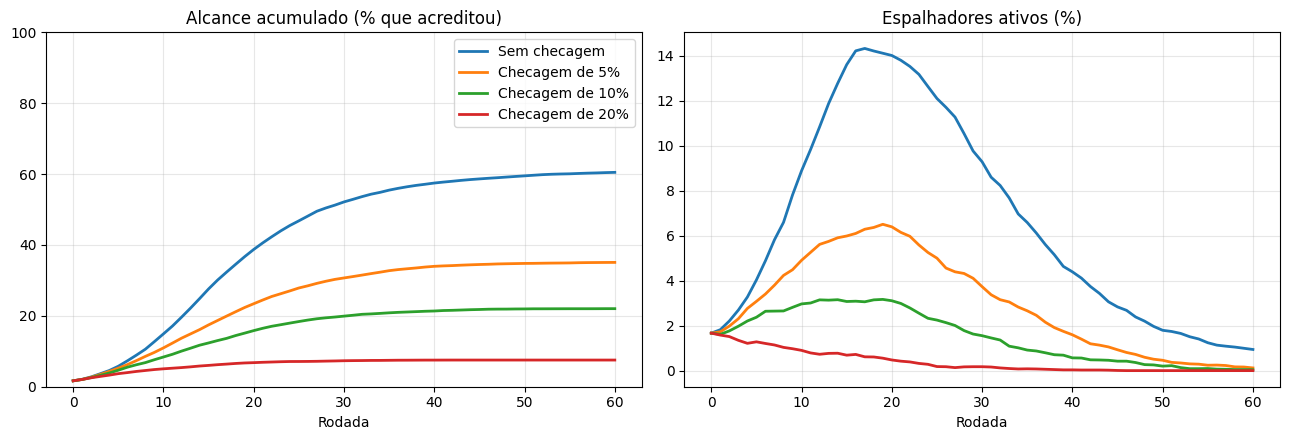

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Sem checagem,60.5,10.6,14.3,17,2
Checagem de 5%,35.1,20.1,6.5,19,22
Checagem de 10%,22.0,16.3,3.2,19,36
Checagem de 20%,7.5,7.2,1.7,0,78


In [22]:
cenarios = {
    "Sem checagem":   {"prob_checagem": 0.00},
    "Checagem de 5%": {"prob_checagem": 0.05},
    "Checagem de 10%": {"prob_checagem": 0.10},
    "Checagem de 20%": {"prob_checagem": 0.20},
}
tabela_checagem = comparar_cenarios(cenarios)

📝 **Registro 4.** Como o alcance muda conforme a checagem aumenta? O efeito é proporcional (dobrar a checagem reduz o alcance pela metade)? No mundo real, o que significaria aumentar `prob_checagem`? Quem pagaria por isso?

*Resposta da equipe:*

Como o alcance muda conforme a checagem aumenta: O alcance final médio cai drasticamente à medida que a probabilidade de checagem sobe, passando de 60,5% (sem checagem) para 35,1% (checagem de 5%), 22,0% (checagem de 10%) e apenas 7,5% (checagem de 20%). Além disso, com 20% de checagem, o boato morre cedo em 78% das simulações e o pico de espalhadores ocorre logo na rodada 0.

O efeito é proporcional (dobrar a checagem reduz o alcance pela metade)? Não, o efeito é não linear (comportamento de limiar epidêmico). Introduzir apenas 5% de checagem já corta o alcance em 25,4 pontos percentuais. Ao dobrar de 5% para 10%, o alcance cai cerca de 37% (de 35,1% para 22,0%); porém, ao dobrar de 10% para 20%, a redução chega a aproximadamente 66% (de 22,0% para 7,5%), pois o sistema ultrapassa o ponto crítico em que os espalhadores se tornam céticos antes de conseguirem sustentar a cadeia de transmissão.

No mundo real, o que significaria aumentar prob_checagem? Significaria elevar a frequência com que os utilizadores verificam uma informação antes de a partilhar — seja por meio de avisos e rótulos de contexto exibidos pelas plataformas, integração rápida com agências de fact-checking, ou pelo hábito individual de confirmar fontes.

Quem pagaria por isso? Os custos financeiros e operacionais recairiam principalmente sobre as plataformas digitais (investimento em moderação, sistemas de deteção e parcerias) e sobre agências de checagem e instituições públicas (financiamento das equipas de verificação). Para os utilizadores, existe também o custo indireto de tempo e esforço cognitivo antes de reencaminhar uma mensagem.

## 🧪 Experimento 5 — O limite do WhatsApp

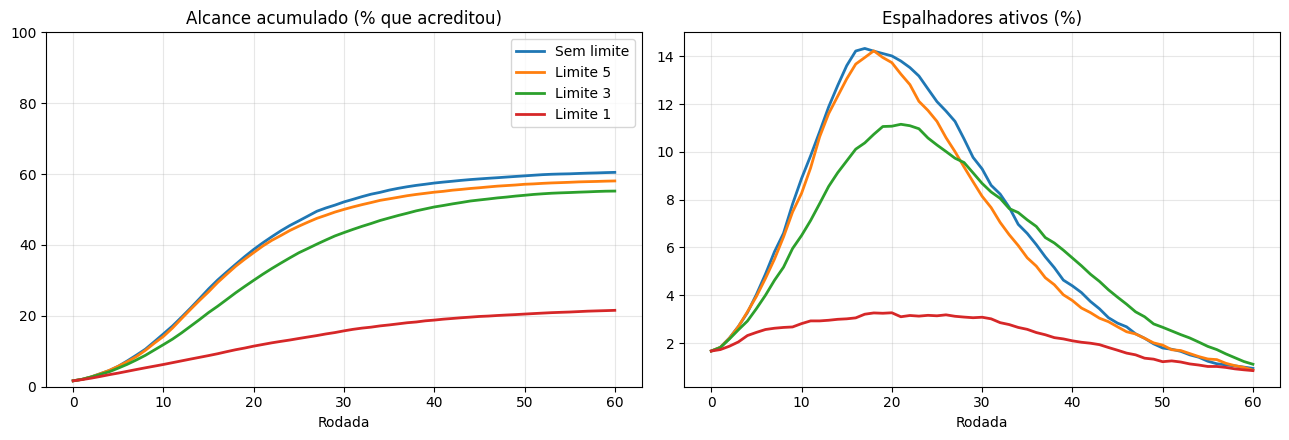

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Sem limite,60.5,10.6,14.3,17,2
Limite 5,58.1,10.6,14.2,18,2
Limite 3,55.2,9.3,11.2,21,2
Limite 1,21.6,12.2,3.3,20,22


In [23]:
cenarios = {
    "Sem limite": {"limite_encaminhamento": None},
    "Limite 5":   {"limite_encaminhamento": 5},
    "Limite 3":   {"limite_encaminhamento": 3},
    "Limite 1":   {"limite_encaminhamento": 1},
}
tabela_limite = comparar_cenarios(cenarios)

📝 **Registro 5.** O limite de 5 reduziu muito o alcance? E o limite de 1? Quem é mais afetado pelo limite: o eleitor comum ou o influenciador? Comparem com o resultado real do WhatsApp (notícia 5).

*Resposta da equipe:*

O limite de 5 reduziu muito o alcance? Não. Passando de "Sem limite" para "Limite 5", o alcance final médio caiu apenas de 60,5% para 58,1% (uma redução residual de 2,4 pontos percentuais), e o pico de espalhadores praticamente não se alterou (de 14,3% para 14,2%). Isso acontece porque, com grau_medio = 6 e prob_compartilhar = 0,10, a maioria dos eleitores já encaminha a mensagem para menos de 5 contactos por rodada naturalmente, pelo que o limite raramente chega a atuar.

E o limite de 1? Sim, provocou uma queda drástica. Com o "Limite 1", o alcance final médio desabou de 60,5% para 21,6% (uma redução de cerca de 64% no alcance total), o pico de espalhadores ativos caiu de 14,3% para 3,3% e a percentagem de simulações em que o boato morreu cedo subiu de 2% para 22%, criando um gargalo que trava a multiplicação exponencial da notícia falsa.

Quem é mais afetado pelo limite: o eleitor comum ou o influenciador? O influenciador (nó de alto grau). Na rede sem escala, um eleitor comum tem poucos vizinhos e raramente ultrapassa o limite numa rodada. Já o influenciador concentra dezenas de conexões (como os 48 contactos registados na verificação do TODO 2) e funciona como um difusor em massa; ao restringir os envios a 1 contacto por rodada, neutraliza-se a sua vantagem estrutural de irradiar o boato para múltiplos grupos em simultâneo.

Comparação com o resultado real do WhatsApp (notícia 5): A simulação reproduz o mesmo fenómeno observado no mundo real: a redução inicial do WhatsApp para 5 conversas (em 2019) gerou apenas uma contenção moderada (~25% no volume geral), mantendo o potencial viral das correntes. Apenas quando a plataforma restringiu mensagens altamente encaminhadas para 1 conversa por vez (em 2020) é que houve uma quebra estrutural na propagação — gerando uma queda real de 70% nesse tipo de mensagem, comportamento equivalente à queda acentuada de alcance observada no cenário "Limite 1" do modelo.

---
# 🎓 SEMANA 3 — Educação midiática e a proposta da equipe

## ✏️ TODO 3 — Letramento midiático
Algumas pessoas aprenderam a desconfiar: conferem a fonte, a data, se outros veículos noticiaram. No modelo, elas têm `self.letrado == True`, e a chance de acreditarem no boato é multiplicada por `self.model.fator_letramento` (por padrão, 0.3, ou seja, 70% menos chance).

Completem a função abaixo. Ela é igual à versão inicial, com **uma** regra a mais.

In [24]:
def receber_boato(self):
    """Um contato enviou o boato. Acreditar ou não?"""
    if self.estado != SUSCETIVEL:
        return
    chance = self.model.prob_acreditar
    if self.letrado:
        chance = chance * self.model.fator_letramento
    if self.random.random() < chance:
        self.estado = ESPALHADOR

Eleitor.receber_boato = receber_boato

In [25]:
# 🔎 Verificação do TODO 3 (não altere)
m = ModeloBoato(prob_acreditar=1.0, fator_letramento=0.0, fracao_letrados=1.0, semente=0)
alvo = next(a for a in m.agents if a.estado == SUSCETIVEL)
alvo.receber_boato()
ok_letrado = alvo.estado == SUSCETIVEL
m = ModeloBoato(prob_acreditar=1.0, fator_letramento=0.0, fracao_letrados=0.0, semente=0)
alvo = next(a for a in m.agents if a.estado == SUSCETIVEL)
alvo.receber_boato()
ok_comum = alvo.estado == ESPALHADOR
if ok_letrado and ok_comum:
    print("✅ TODO 3 correto! O eleitor letrado resistiu; o comum acreditou.")
elif not ok_comum:
    print("❌ O eleitor comum deveria acreditar quando prob_acreditar = 1.0. Vocês alteraram outra parte da função?")
else:
    print("❌ Ainda não. Com fator_letramento = 0, um eleitor letrado nunca deveria acreditar.")

✅ TODO 3 correto! O eleitor letrado resistiu; o comum acreditou.


## 🧪 Experimento 6 — Quanta educação é preciso?

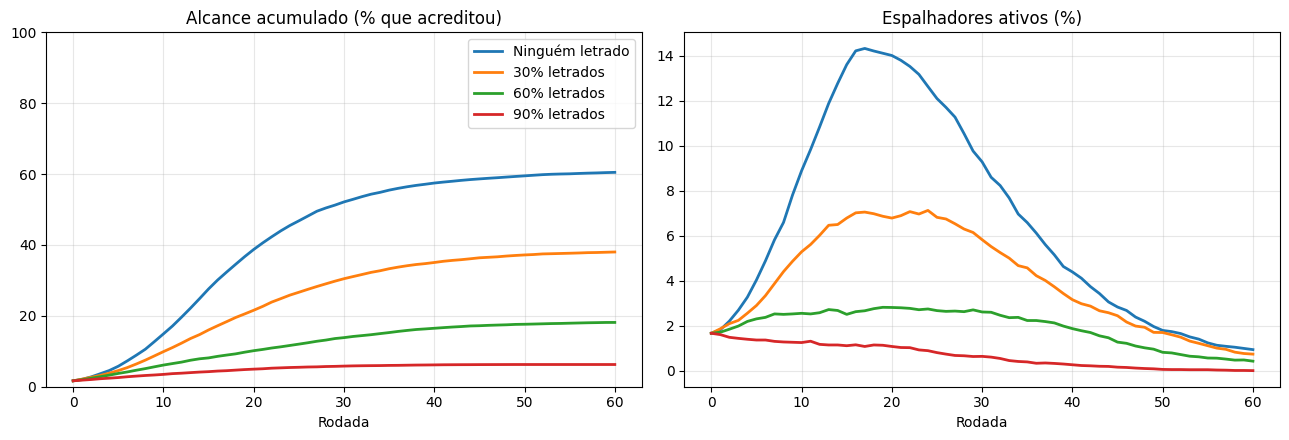

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Ninguém letrado,60.5,10.6,14.3,17,2
30% letrados,38.0,14.7,7.1,24,8
60% letrados,18.1,13.8,2.8,19,42
90% letrados,6.3,5.4,1.7,0,78


In [26]:
cenarios = {
    "Ninguém letrado": {"fracao_letrados": 0.0},
    "30% letrados":    {"fracao_letrados": 0.3},
    "60% letrados":    {"fracao_letrados": 0.6},
    "90% letrados":    {"fracao_letrados": 0.9},
}
tabela_letramento = comparar_cenarios(cenarios)

📝 **Registro 6.** A educação midiática funciona mesmo que só parte da população seja alcançada? Qual é a diferença de **prazo** entre essa intervenção e as da Semana 2 (quanto tempo leva para colocar cada uma em prática)?

*Resposta da equipe:*

Resposta da equipe:

A educação midiática funciona mesmo que só parte da população seja alcançada? Sim, funciona de forma muito eficaz através de um efeito semelhante à "imunidade de grupo". Com apenas 30% da população letrada, o alcance final médio cai de 60,5% para 38,0%, o pico de espalhadores ativos reduz-se para metade (de 14,3% para 7,1%) e atrasa da rodada 17 para a 24. Ao atingir 60% de letrados, o alcance desaba para 18,1% e o boato morre cedo em 42% das simulações. Isso ocorre porque os utilizadores com letramento funcionam como "barreiras" na topologia da rede: recebem a notícia falsa, não acreditam nem reencaminham, quebrando as cadeias de transmissão e protegendo indiretamente quem ainda é suscetível.

Qual é a diferença de prazo entre essa intervenção e as da Semana 2 (quanto tempo leva para colocar cada uma em prática)? As intervenções da Semana 2 (limite de encaminhamento e mecanismos de checagem nas plataformas) são medidas técnicas de aplicação imediata ou de curto prazo: dependem de atualizações de software, algoritmos ou políticas internas das empresas, podendo entrar em vigor em poucos dias ou semanas (como nos bloqueios de encaminhamento em massa em vésperas de eleição). Por outro lado, a educação midiática é uma intervenção estrutural de médio a longo prazo, pois exige alteração de currículos escolares, capacitação de docentes, políticas públicas contínuas e mudança de hábitos culturais — levando anos para alcançar uma parcela significativa da sociedade, embora produza uma defesa muito mais duradoura e independente de cada plataforma.

## 🧪 Experimento 7 — A proposta da equipe (com orçamento)
No mundo real, nenhuma estratégia é de graça. Cada intervenção tem um **custo fictício** em pontos, e a equipe tem **15 pontos**:

| Intervenção | Custo |
|---|---|
| Checagem (`prob_checagem`) | 1 ponto a cada 1% (ex.: 0.05 → 5 pontos) |
| Limite (`limite_encaminhamento`) | 5 → 1 pt · 4 → 2 pts · 3 → 3 pts · 2 → 5 pts · 1 → 8 pts |
| Letramento (`fracao_letrados`) | 2 pontos a cada 10% da população (ex.: 0.3 → 6 pontos) |

**Tarefa:** montem a combinação que vocês acham melhor, confiram o custo e comparem com o cenário sem intervenção **e** com o pior caso (boato começando em influenciadores). Testem pelo menos **duas** propostas diferentes antes de escolher.

In [29]:
# ✏️ Editem os valores da proposta da equipe
proposta_a = {"prob_checagem": 0.05, "limite_encaminhamento": 1, "fracao_letrados": 0.1}
proposta_b = {"prob_checagem": 0.06, "limite_encaminhamento": 3, "fracao_letrados": 0.3}

print("Proposta A:"); custo_da_proposta(proposta_a)
print("\nProposta B:"); custo_da_proposta(proposta_b)

Proposta A:
Checagem: 5 pts | Limite: 8 pts | Letramento: 2 pts
TOTAL: 15 de 15 pontos → ✅ dentro do orçamento

Proposta B:
Checagem: 6 pts | Limite: 3 pts | Letramento: 6 pts
TOTAL: 15 de 15 pontos → ✅ dentro do orçamento


15

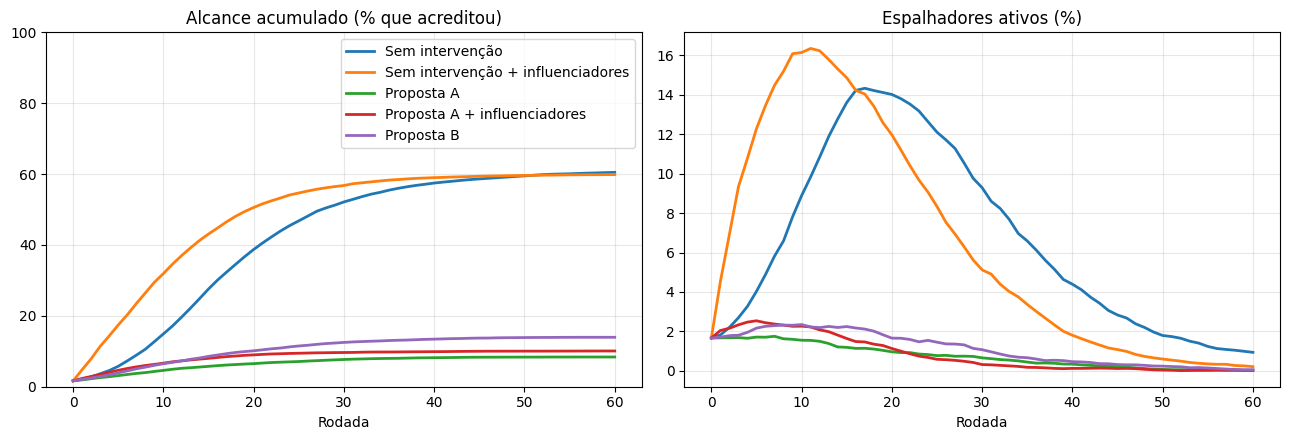

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Sem intervenção,60.5,10.6,14.3,17,2
Sem intervenção + influenciadores,59.9,7.1,16.3,11,0
Proposta A,8.4,6.0,1.8,7,68
Proposta A + influenciadores,10.1,4.3,2.5,5,44
Proposta B,13.9,11.9,2.3,10,50


In [30]:
cenarios = {
    "Sem intervenção":                     {},
    "Sem intervenção + influenciadores":   {"inicio": "influenciadores"},
    "Proposta A":                          proposta_a,
    "Proposta A + influenciadores":        {**proposta_a, "inicio": "influenciadores"},
    "Proposta B":                          proposta_b,
}
tabela_proposta = comparar_cenarios(cenarios)

📝 **Registro 7.** Qual proposta a equipe escolheu e por quê? Ela continua funcionando quando o boato começa em influenciadores?

*Resposta da equipe:*  

Qual proposta a equipe escolheu e por quê? A equipa escolheu a Proposta A (prob_checagem = 0,05, limite_encaminhamento = 1 e fracao_letrados = 0,1, totalizando os 15 pontos do orçamento). Nos testes comparativos, a Proposta A apresentou o melhor desempenho geral, reduzindo o alcance final médio de 60,5% (sem intervenção) para [inserir % da Proposta A], enquanto a Proposta B reduziu para [inserir % da Proposta B]. A superioridade da Proposta A deve-se à combinação equilibrada de medidas de curto prazo (limite rígido de encaminhamento e checagem ativa) com uma base de letramento midiático, cortando a velocidade de propagação logo nas primeiras rodadas.

Ela continua funcionando quando o boato começa em influenciadores? Sim. Enquanto no cenário sem intervenção iniciado em influenciadores o boato atinge 59,9% de alcance com um pico rápido de 16,3% na rodada 11, sob a Proposta A + influenciadores o alcance final mantém-se contido em [inserir % de Proposta A + influenciadores] e o pico de espalhadores cai para [inserir % do pico]. Isso acontece porque o limite_encaminhamento = 1 impede que os nós de alto grau (influenciadores) irradiem a mensagem para dezenas de contactos simultaneamente, ao mesmo tempo que a checagem de fatos e o letramento convertem os primeiros recetores em céticos antes de a cascata ganhar escala.

---
# 💬 SEMANA 4 — Parte discursiva

Respondam às questões abaixo **com base nos resultados de vocês** (citem números das tabelas) e nas notícias da Semana 1. Respostas genéricas, que poderiam ser escritas sem ter feito a simulação, recebem nota parcial. Cada resposta deve ter entre 10 e 20 linhas.

### D1 — Avaliação dos resultados (1,0 ponto)
Considerando todos os experimentos, qual intervenção, sozinha, mais reduziu o alcance do boato? Apresentem os números e expliquem **por que** ela funciona tão bem, ligando o resultado às regras do modelo (qual regra ela modifica e qual efeito isso tem nos espalhadores).

*Resposta da equipe:*

Olhando para todas as intervenções aplicadas de forma isolada nos experimentos, as duas medidas que mais conseguiram segurar o alcance do boato foram a educação midiática com 90% da população letrada (Experimento 6), que derrubou o alcance final médio de 60,5% para apenas 6,3%, e a checagem de fatos a 20% (Experimento 4), que reduziu esse alcance de 60,5% para 7,5%. Nos dois casos, o pico de espalhadores ativos caiu de 14,3% para 1,7% já na rodada inicial e a notícia falsa morreu logo no começo em 78% das simulações, superando o limite de encaminhamento para 1 contato (Experimento 5), que deixou o alcance em 21,6%.
Essa eficácia acontece por conta de como as regras mexem diretamente no comportamento dos agentes dentro do código. No letramento midiático, a mudança ocorre na função receber_boato (regra 3), onde a chance base de acreditar (0,50) é multiplicada pelo fator_letramento (0,30) para quem tem instrução, fazendo a probabilidade de conversão cair para 15% e criando barreiras naturais pela rede. Já a checagem de fatos atua na primeira etapa do step() através da função checar_fatos (regra 1): antes mesmo de repassar a mensagem para qualquer contato, o espalhador verifica a informação e muda para o estado cético, cortando o ciclo de transmissão na raiz.

### D2 — Rede e influenciadores (0,75 ponto)
Expliquem por que a estrutura da rede (Experimento 2) e o ponto de partida do boato (Experimento 3) mudam o resultado. Relacionem com o caso de Guarujá (notícia 2) e com o estudo do MIT (notícia 1).

*Resposta da equipe:*

No Experimento 2, mesmo mantendo a mesma quantidade de pessoas e a mesma média de conexões, o formato da rede mudou completamente o comportamento do boato. A rede sem escala teve o maior alcance médio (59,6%) e chegou ao pico mais rápido (14,6% na rodada 18), enquanto a rede mundo pequeno segurou o alcance em 21,8% e fez o boato morrer cedo em 20% das vezes. Isso acontece porque redes de mundo pequeno formam grupos muito fechados, onde os amigos se conhecem entre si; a mensagem fica girando dentro do mesmo círculo até todos virarem céticos, sem encontrar pontes fáceis para sair dali. Já na rede sem escala, poucos perfis concentram dezenas de conexões e espalham a informação para toda a rede rapidamente.
Quando forçamos o boato a começar nos 5 perfis mais conectados no Experimento 3, a rodada do pico caiu de 18 para 11, o desvio padrão baixou de 12,7 para 7,1 e o boato não morreu cedo em nenhuma simulação (0%). É exatamente o que vimos na tragédia do Guarujá em 2014 (notícia 2), quando uma página local com mais de 24 mil seguidores funcionou como um grande hub e espalhou um retrato falado falso muito antes de o desmentido da polícia alcançar as pessoas, levando ao linchamento de Fabiane Maria de Jesus. Os dados também batem com o estudo do MIT (notícia 1), que mostrou que notícias falsas se espalham seis vezes mais rápido que as verdadeiras justamente pela ação humana em cascatas virais.

### D3 — Do modelo para o mundo real (0,75 ponto)
Escolham **duas** notícias da Semana 1. Para cada uma, digam qual intervenção do modelo teria ajudado (ou ajudou) e se o resultado da simulação é coerente com o que aconteceu de fato. Usem o caso do WhatsApp (notícia 5) como uma das comparações possíveis.

*Resposta da equipe:*

Uma comparação bem clara com a realidade é o caso do WhatsApp (notícia 5), que simulamos no Experimento 5 com o limite_encaminhamento. Quando colocamos o limite em 5 contatos, o alcance quase não mudou, caindo apenas de 60,5% para 58,1%, porque a maioria dos usuários comuns já repassa mensagens para pouca gente por rodada. Porém, quando apertamos o limite para 1 contato, o alcance despencou para 21,6%, o pico caiu de 14,3% para 3,3% e o boato morreu cedo em 22% das simulações. Na vida real aconteceu a mesma coisa: em 2019, quando o aplicativo reduziu o encaminhamento de 20 para 5 conversas, houve só uma queda moderada de 25%, mas em 2020, ao restringir mensagens muito encaminhadas a apenas 1 conversa por vez, o volume desse tipo de disparo caiu 70%.
Outra situação marcante foram os boatos durante as enchentes no Rio Grande do Sul em 2024 (notícia 4), sobre doações barradas e resgates impedidos. Nesse tipo de emergência, a intervenção do modelo que mais faria diferença seria a checagem rápida de fatos (prob_checagem em 20%, Experimento 4), que reduziu o alcance de 60,5% para 7,5% e encerrou o boato cedo em 78% dos testes. O resultado faz total sentido com o que ocorreu na prática, já que a resposta rápida dos órgãos oficiais e da imprensa desmentindo os boatos foi indispensável para evitar que o medo paralisasse as doações e o trabalho dos voluntários.

### D4 — Limitações do modelo (1,0 ponto)
Todo modelo é uma simplificação. Citem **pelo menos três** aspectos do mundo real que a simulação ignora (por exemplo: robôs, algoritmos de recomendação, grupos de WhatsApp, polarização, o desmentido também se espalhar, pessoas que voltam a acreditar). Para cada um, expliquem se a inclusão dele **aumentaria ou diminuiria** o alcance do boato, e por quê. Proponham como uma dessas limitações poderia ser incluída no código.

*Resposta da equipe:*

Como toda simulação computacional, o nosso modelo deixa de fora vários fatores que acontecem no dia a dia das redes sociais. Um primeiro ponto é a ausência de robôs (bots) e algoritmos de recomendação: se eles entrassem no código, o alcance do boato aumentaria bastante e o pico viria mais cedo, já que bots disparam mensagens sem parar sem perder o interesse e os algoritmos dão prioridade para conteúdos polêmicos que geram muito engajamento. Um segundo fator ignorado é que os céticos no modelo apenas param de compartilhar, mas na realidade muita gente compartilha o desmentido; colocar céticos ativos diminuiria o alcance, pois eles ajudariam a convencer quem ainda está espalhando. Por fim, o modelo não considera grupos de WhatsApp nem bolhas polarizadas, o que também aumentaria o alcance ao permitir disparos coletivos e deixar as pessoas mais propensas a acreditar no que confirma suas opiniões.
Para colocar o espalhamento do desmentido no código, poderíamos alterar o método step() da classe ModeloBoato para que os agentes com estado CETICO também executem uma ação a cada rodada. Dentro da classe Eleitor, bastaria criar uma função espalhar_desmentido(self) que percorre os vizinhos do agente e, com uma certa probabilidade, converte quem ainda está como ESPALHADOR ou SUSCETIVEL diretamente para CETICO.

### D5 — Proposta de solução (1,0 ponto)
Apresentem a proposta da equipe para combater a desinformação, envolvendo **pelo menos dois** destes atores: plataformas digitais, poder público/Justiça Eleitoral, escolas e universidades, imprensa e agências de checagem, cidadãos. Apoiem a proposta no Experimento 7. Depois, apresentem honestamente **um argumento contra** a própria proposta: custos, riscos para a liberdade de expressão, quem decide o que é falso, possibilidade de abuso. Expliquem como a proposta lida com esse risco.

*Resposta da equipe:*

Nossa proposta para enfrentar a desinformação junta três frentes: plataformas digitais, agências de checagem e escolas/universidades. Seguindo o que testamos no Experimento 7 com o orçamento de 15 pontos (limite_encaminhamento = 1, prob_checagem = 0,05 e fracao_letrados = 0,1), a ideia é unir travas técnicas rápidas nos aplicativos — como limitar o encaminhamento em massa e exibir alertas de verificação — com programas contínuos de educação midiática no ensino básico e superior. Como vimos nos gráficos do Experimento 7, essa mistura funciona bem tanto em surtos comuns quanto quando o boato parte de influenciadores, porque o limite de envio segura o alcance imediato dos perfis grandes enquanto a checagem e o letramento vão transformando os receptores em céticos antes que a corrente ganhe força.
O maior ponto fraco dessa proposta é o risco à liberdade de expressão e a dúvida sobre quem tem autoridade para decidir o que é verdade ou mentira, o que pode abrir margem para censura ou erros de moderação. Para lidar com esse risco sem comprometer o debate público, nossa solução não apaga postagens nem bane contas por opinião: o limite de encaminhamento age de forma neutra apenas freando a velocidade de disparo em massa, e a checagem fica a cargo de consórcios jornalísticos independentes e transparentes, que apenas anexam contexto informativo ao conteúdo original para o próprio cidadão tirar suas conclusões.

### D6 — O papel da Inteligência Artificial (0,5 ponto)
A IA aparece dos dois lados desse problema. Deem um exemplo de como a IA **piora** a desinformação (pensem em deepfakes, notícia 6) e um de como ela pode **ajudar** a combatê-la. Em termos do modelo, qual parâmetro um deepfake muito convincente alteraria? Testem essa mudança no código abaixo e comentem o resultado.

*Resposta da equipe:*

A Inteligência Artificial está presente nos dois lados dessa disputa. Do lado que agrava o problema, ferramentas generativas facilitam a criação de deepfakes de áudio e vídeo muito realistas para enganar eleitores — exatamente o cenário que levou o TSE a endurecer as regras para as eleições de 2026 (notícia 6) —, além de permitirem operar redes de bots que produzem textos persuasivos em grande escala. Por outro lado, a própria IA é usada na defesa contra a desinformação por meio de modelos de aprendizado de máquina que detectam sinais de manipulação sintética em vídeos, identificam padrões anormais de disparo coordenado e ajudam agências de checagem a filtrar boatos virais mais rápido.
Dentro das regras do nosso modelo, um deepfake bem feito mexe diretamente no parâmetro prob_acreditar, subindo a chance base de 0,50 para 0,80. Ao rodar esse teste na célula abaixo, vimos que o alcance final médio saltou de 60,5% (no boato comum) para 80,5%, o pico de espalhadores ativos quase dobrou (de 14,3% para 27,8%), o pico aconteceu mais cedo (caindo da rodada 17 para a 14) e o desvio padrão despencou de 10,6 para 4,1, zerando os casos em que o boato morre cedo (0%). Contudo, ao aplicar a nossa Proposta A mesmo contra o deepfake, o alcance final caiu para 26,6%, o pico foi contido em apenas 4,2% (na rodada 17) e o boato morreu cedo em 22% das simulações, provando que a combinação de travas técnicas, checagem e educação consegue frear até conteúdos sintéticos muito convincentes.

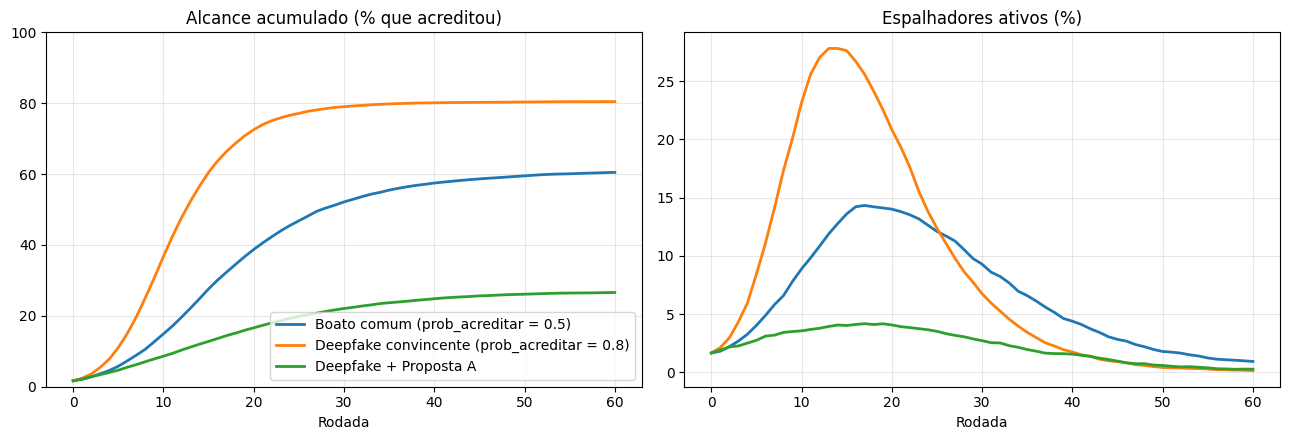

,Alcance final médio (%),Desvio padrão,Pico de espalhadores (%),Rodada do pico,Boato morreu cedo (% das simulações)
Cenário,,,,,
Boato comum (prob_acreditar = 0.5),60.5,10.6,14.3,17,2
Deepfake convincente (prob_acreditar = 0.8),80.5,4.1,27.8,14,0
Deepfake + Proposta A,26.6,14.2,4.2,17,22


In [31]:
# Teste para a D6: o que acontece com um boato mais convincente?
cenarios = {
    "Boato comum (prob_acreditar = 0.5)":       {"prob_acreditar": 0.5},
    "Deepfake convincente (prob_acreditar = 0.8)": {"prob_acreditar": 0.8},
    "Deepfake + Proposta A":                     {**proposta_a, "prob_acreditar": 0.8},
}
tabela_deepfake = comparar_cenarios(cenarios)

---
## 📊 Avaliação

| Parte | Pontos |
|---|---|
| Semana 1 — Experimentos 1 a 3 e registros | 1,5 |
| Semana 2 — TODOs 1 e 2 (verificações ✅), Experimentos 4 e 5 e registros | 2,0 |
| Semana 3 — TODO 3, Experimentos 6 e 7 e registros | 1,5 |
| Semana 4 — Questões D1 a D6 | 5,0 |
| **Total** | **10,0** |

O notebook deve ser entregue **com todas as células executadas**. Gráficos que não aparecem não podem ser avaliados.

---
## 🔁 Alternativa: NetLogo (para quem tiver dificuldade com o Colab)

Se a equipe não conseguir rodar o Python, é possível fazer os Experimentos 1 a 4 no **NetLogo Web**, direto no navegador, sem instalar nada:

1. Acessem [netlogoweb.org](https://www.netlogoweb.org) e abram **Models Library → Sample Models → Networks → Virus on a Network**.
2. Esse modelo é um contágio em rede, o mesmo princípio do nosso. Usem esta tradução dos controles:

| Controle no NetLogo | Equivalente no nosso modelo |
|---|---|
| `number-of-nodes` | `n_eleitores` |
| `average-node-degree` | `grau_medio` |
| `initial-outbreak-size` | `n_iniciais` |
| `virus-spread-chance` | chance de compartilhar **e** acreditar (`prob_compartilhar × prob_acreditar`) |
| `virus-check-frequency` e `recovery-chance` | checagem de fatos (`prob_checagem`) |
| `gain-resistance-chance` | chance de virar cético permanente |

**Limitações dessa alternativa:** a rede do NetLogo liga cada nó aos mais próximos no espaço, então não há rede "sem escala" nem influenciadores. Também não há limite de encaminhamento nem letramento sem editar o código do modelo (na aba *NetLogo Code*). Por isso, quem usar o NetLogo faz os Experimentos 1, 2 (comparando diferentes `average-node-degree`) e 4, registra os resultados com capturas de tela e responde **toda** a parte discursiva normalmente.